# (c) Design study

Four questions an inference-chip architect would ask, answered with the
model. All numbers are **model predictions** (pure roofline, no overhead), not
measurements. They are upper bounds on throughput and lower bounds on energy.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "notebooks"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotstyle as ps
from perfmodel import load_model, load_chip, predict_step
ps.apply()
pd.set_option("display.precision", 3)

## 1. How much SRAM does it take to hold a 1B model at 4-bit?

Weights only, plus the KV cache, which also has to live somewhere. 4.25 bits
models group-wise quantization with an fp16 scale per 128 weights (+0.125
bit/weight). Llama 3.2 1B ties its embedding and LM head, so the 128k x 2048
table is read in full every step and has to be resident too.

In [2]:
from perfmodel.ops import tensor_footprints
rows = []
for name in ["llama3.2-1b", "qwen2.5-1.5b"]:
    for wb in [16, 8, 4, 4.25]:
        m = load_model(name).with_(weight_bits=wb)
        fp = tensor_footprints(m, 1, 1)
        fp.pop("kv_cache")
        rows.append({"model": m.name, "weight_bits": wb,
                     "weights_MiB": sum(fp.values()) / 2**20,
                     "of_which_embed_MiB": fp["embed"] / 2**20,
                     "KV_MiB_b1_ctx2k": m.kv_cache_bytes(1, 2048) / 2**20,
                     "KV_MiB_b16_ctx8k": m.kv_cache_bytes(16, 8192) / 2**20})
sram = pd.DataFrame(rows)
sram.round(1)

,model,weight_bits,weights_MiB,of_which_embed_MiB,KV_MiB_b1_ctx2k,KV_MiB_b16_ctx8k
0,Llama-3.2-1B,16.0,2357.1,501.0,64.0,4096.0
1,Llama-3.2-1B,8.0,1178.6,250.5,64.0,4096.0
2,Llama-3.2-1B,4.0,589.4,125.2,64.0,4096.0
3,Llama-3.2-1B,4.2,626.2,133.1,64.0,4096.0
4,Qwen2.5-1.5B,16.0,2944.4,445.1,56.0,3584.0
5,Qwen2.5-1.5B,8.0,1472.3,222.6,56.0,3584.0
6,Qwen2.5-1.5B,4.0,736.3,111.3,56.0,3584.0
7,Qwen2.5-1.5B,4.2,782.3,118.2,56.0,3584.0


**Answer.** Llama 3.2 1B at 4-bit needs **≈ 589 MiB** for weights (≈ 626 MiB
with group scales). The tied 128k-vocab embedding alone is 125 MiB of that.
The KV cache adds 64 MiB per 2k-token sequence at 16-bit, so a 1 GiB SRAM
holds the model plus a handful of 2k sequences. A 16-sequence 8k-token batch
(4 GiB of KV) has to spill to DRAM or use KV quantization. Under 512 MiB the
model doesn't fit, and decode falls back to DRAM speed.

### What actually lands in SRAM

SRAM-X (1 GiB) running Llama 3.2 1B at batch 1 and context 2048, by weight
precision. The greedy policy fills SRAM in order of bytes read per byte
stored. Whatever doesn't fit is read from DRAM every step.

,weights,resident_MiB,spilled_MiB,act_buffer_MiB,tok_s
0,16-bit,1023.8,1397.4,0.2,556.1
1,8-bit,1023.8,218.9,0.2,3438.8
2,4-bit,653.4,0.0,0.2,140508.2


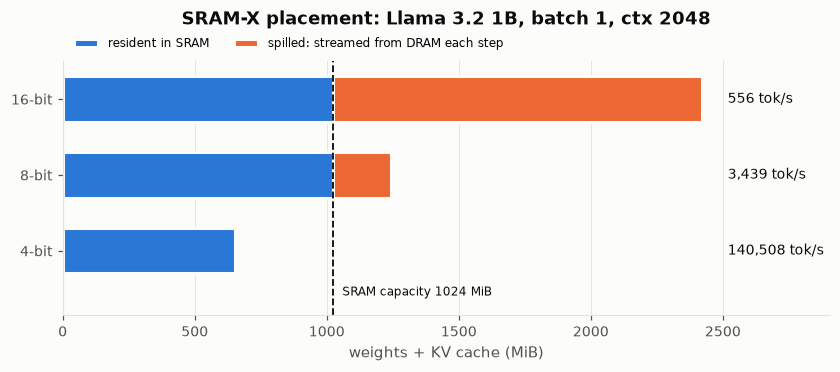

In [3]:
m1, sx = load_model("llama3.2-1b"), load_chip("sram-accel")
rows = []
for wb in [16, 8, 4]:
    r = predict_step(m1.with_(weight_bits=wb), sx, 1, 2048, 1)
    p = r.placement
    resident = sum(p.footprint[t] * f for t, f in p.sram_fraction.items())
    total = sum(p.footprint.values())
    rows.append({"weights": f"{wb}-bit", "resident_MiB": resident / 2**20,
                 "spilled_MiB": (total - resident) / 2**20,
                 "act_buffer_MiB": p.activation_reserve / 2**20, "tok_s": r.tokens_per_s})
place = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 3))
ys = np.arange(len(place))[::-1]
ax.barh(ys, place.resident_MiB, color=ps.SERIES[0], height=0.6, label="resident in SRAM",
        edgecolor=ps.SURFACE, linewidth=2)
ax.barh(ys, place.spilled_MiB, left=place.resident_MiB, color=ps.SERIES[1], height=0.6,
        label="spilled: streamed from DRAM each step", edgecolor=ps.SURFACE, linewidth=2)
cap = sx.sram_bytes / 2**20
xmax = place.eval("resident_MiB + spilled_MiB").max()
ax.axvline(cap, color=ps.INK, lw=1.2, ls="--")
ax.annotate(f"SRAM capacity {cap:.0f} MiB", (cap, ys[-1] - 0.55), xytext=(6, 0),
            textcoords="offset points", fontsize=8, color=ps.INK, va="center")
for y, row in zip(ys, place.itertuples()):
    ax.text(xmax * 1.04, y, f"{row.tok_s:,.0f} tok/s", va="center", fontsize=9, color=ps.INK)
ax.set_yticks(ys, place.weights)
ax.set(xlabel="weights + KV cache (MiB)", xlim=(0, xmax * 1.2), ylim=(ys[-1] - 0.85, ys[0] + 0.5))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=2, fontsize=8)
ax.set_title("SRAM-X placement: Llama 3.2 1B, batch 1, ctx 2048", pad=24)
ps.save(fig, "sram_placement");
place.round(1)

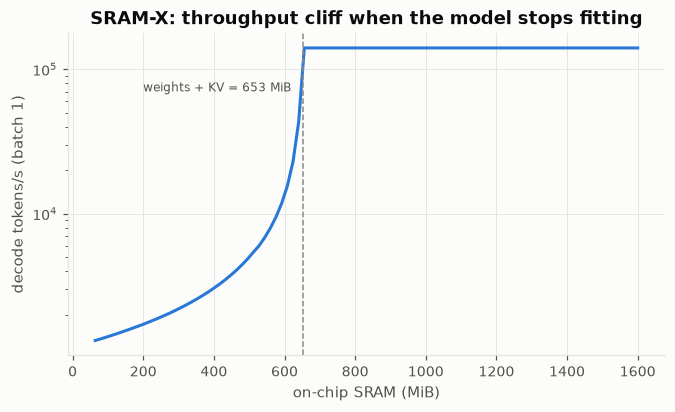

In [4]:
# The SRAM cliff: tokens/s on SRAM-X as SRAM capacity grows (1B, 4-bit, batch 1, ctx 2048)
m4, sx = load_model("llama3.2-1b").with_(weight_bits=4), load_chip("sram-accel")
caps = np.arange(64, 1601, 16)
tps = [predict_step(m4, sx.with_(sram_mib=float(c)), 1, 2048, 1).tokens_per_s for c in caps]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(caps, tps, color=ps.SERIES[0])
need = (sram.query("model == 'Llama-3.2-1B' and weight_bits == 4").weights_MiB.item()
        + m4.kv_cache_bytes(1, 2049) / 2**20)
ax.axvline(need, color=ps.NEUTRAL, ls="--", lw=1)
ax.annotate(f"weights + KV = {need:.0f} MiB", (need, max(tps) * 0.5), xytext=(-8, 0),
            textcoords="offset points", ha="right", fontsize=8, color=ps.INK_2)
ax.set(yscale="log", xlabel="on-chip SRAM (MiB)", ylabel="decode tokens/s (batch 1)",
       title="SRAM-X: throughput cliff when the model stops fitting")
ps.save(fig, "design_sram_cliff");

Two regimes. Below the fit point, step time is set by whatever still
streams from DRAM, since SRAM and DRAM run in parallel and the slower level
wins. Each extra MiB of SRAM removes DRAM bytes, so throughput rises
hyperbolically. When the last byte fits, the DRAM path drops out and the
step jumps to SRAM speed: a ~10x cliff over the final few MiB. Sizing SRAM
"just under" the model forfeits most of the benefit.

## 2. At what batch size does decode flip to compute-bound?

For one weight matmul the intensity is $2BdK / (dK \cdot w_b) = 2B/w_b$
FLOP/byte, so it crosses the ridge at $B^* = \text{ridge} \cdot w_b / 2$. At
bf16 that is $B^* \approx$ ridge itself. The **whole step** is a different
question, because attention's KV reads scale with $B \times C$ and are never
amortized.

In [5]:
m = load_model("llama3.2-1b")
def first_batch(chip, ctx, test, max_b=2**15):
    b = 1
    while b <= max_b:
        if test(predict_step(m, chip, b, ctx, 1)):
            return b
        b *= 2
    return None
rows = []
for cn in ["a100", "h100", "jetson-orin", "sram-accel"]:
    c = load_chip(cn)
    ridge = c.peak_flops(m.compute_dtype) / c.dram_bw
    for ctx in [128, 512, 4096]:
        mm = first_batch(c, ctx, lambda r: {o.name: o for o in r.ops}["mlp_up"].bound == "compute")
        st = first_batch(c, ctx, lambda r: r.compute_bound_fraction > 0.5)
        rows.append({"chip": cn, "context": ctx, "ridge_FLOP/B": round(ridge),
                     "B* analytic (bf16)": round(ridge),
                     "mlp_up flips at B (pow2)": mm,
                     "whole step >50% compute-bound at B": st or "never (<= 32768)"})
flip = pd.DataFrame(rows)
flip

,chip,context,ridge_FLOP/B,B* analytic (bf16),mlp_up flips at B (pow2),whole step >50% compute-bound at B
0,a100,128,153,153,256,256
1,a100,512,153,153,256,never (<= 32768)
2,a100,4096,153,153,256,never (<= 32768)
3,h100,128,295,295,512,512
4,h100,512,295,295,512,never (<= 32768)
5,h100,4096,295,295,512,never (<= 32768)
6,jetson-orin,128,208,208,256,256
7,jetson-orin,512,208,208,256,never (<= 32768)
8,jetson-orin,4096,208,208,256,never (<= 32768)
9,sram-accel,128,488,488,512,512


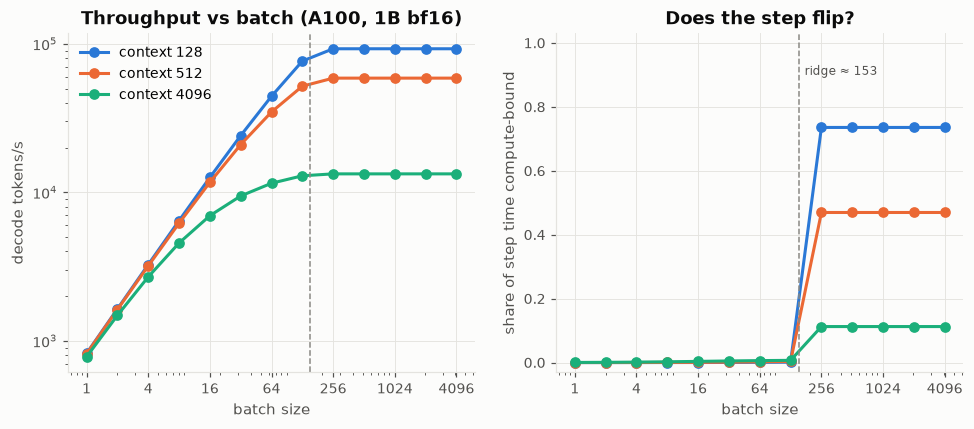

In [6]:
a100 = load_chip("a100")
bs = 2 ** np.arange(0, 13)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
for i, ctx in enumerate([128, 512, 4096]):
    rs = [predict_step(m, a100, int(b), ctx, 1) for b in bs]
    axes[0].plot(bs, [r.tokens_per_s for r in rs], marker="o", color=ps.SERIES[i],
                 label=f"context {ctx}")
    axes[1].plot(bs, [r.compute_bound_fraction for r in rs], marker="o", color=ps.SERIES[i],
                 label=f"context {ctx}")
ridge = a100.peak_flops("bf16") / a100.dram_bw
for ax in axes:
    ax.axvline(ridge, color=ps.NEUTRAL, ls="--", lw=1)
    ax.set(xscale="log", xlabel="batch size")
    ax.set_xticks(bs[::2], [str(b) for b in bs[::2]])
axes[0].set(yscale="log", ylabel="decode tokens/s", title="Throughput vs batch (A100, 1B bf16)")
axes[1].set(ylabel="share of step time compute-bound", ylim=(-0.03, 1.03),
            title="Does the step flip?")
axes[1].annotate(f"ridge ≈ {ridge:.0f}", (ridge, 0.9), xytext=(4, 0), textcoords="offset points",
                 fontsize=8, color=ps.INK_2)
axes[0].legend()
ps.save(fig, "design_batch_flip");

**Answer.** The weight matmuls flip at **B ≈ 153 on A100** and ≈ 295 on H100
(bf16), matching $B^* =$ ridge. The full decode step of Llama 3.2 1B
**never flips at contexts ≥ 512** on any of these chips (searched to
B = 32768). It flips only at short context (128 tokens: B ≈ 256 on A100), and
even there it saturates at about 75% compute-bound time. Per sequence, KV traffic per step is
$L \cdot 2 \cdot C \cdot d_{kv} \cdot 2$ bytes (32 KiB per cached token here). It
grows with batch exactly as fast as the matmul FLOPs, so by the time the
weights are amortized, attention has become the memory-bound bottleneck.
Large-batch serving is therefore limited by KV bandwidth (and capacity: 4k
sequences at 512 tokens is 64 GiB of KV). That is why KV quantization, GQA/MLA
and paged or offloaded KV matter more than raw TFLOPs.

## 3. What does weight quantization buy (tokens/s and energy)?

In [7]:
rows = []
for cn in ["a100", "sram-accel"]:
    c = load_chip(cn)
    for name in ["llama3.2-1b", "llama3-8b"]:
        for wb in [16, 8, 4]:
            for b in [1, 64]:
                r = predict_step(load_model(name).with_(weight_bits=wb), c, b, 1024, 1)
                rows.append({"chip": cn, "model": name, "weight_bits": wb, "batch": b,
                             "tokens_per_s": r.tokens_per_s,
                             "mJ_per_token": r.energy_per_token_j * 1e3,
                             "dram_GB_per_step": r.dram_bytes / 1e9,
                             "compute_bound_frac": r.compute_bound_fraction})
quant = pd.DataFrame(rows)
base = quant[quant.weight_bits == 16].set_index(["chip", "model", "batch"])
quant["speedup_vs_16bit"] = quant.apply(
    lambda r: r.tokens_per_s / base.loc[(r.chip, r.model, r.batch)].tokens_per_s, axis=1)
quant["energy_vs_16bit"] = quant.apply(
    lambda r: r.mJ_per_token / base.loc[(r.chip, r.model, r.batch)].mJ_per_token, axis=1)
quant.round(3)

,chip,model,weight_bits,batch,tokens_per_s,mJ_per_token,dram_GB_per_step,compute_bound_frac,speedup_vs_16bit,energy_vs_16bit
0,a100,llama3.2-1b,16,1,812.819,80.221,2.508,0.000,1.000,1.000
1,a100,llama3.2-1b,16,64,26991.233,4.311,4.817,0.004,1.000,1.000
2,a100,llama3.2-1b,8,1,1601.975,41.666,1.273,0.000,1.971,0.519
3,a100,llama3.2-1b,8,64,36260.198,3.709,3.581,0.005,1.343,0.860
4,a100,llama3.2-1b,4,1,3113.313,22.388,0.655,0.000,3.830,0.279
5,a100,llama3.2-1b,4,64,39513.580,3.407,2.963,0.318,1.464,0.790
6,a100,llama3-8b,16,1,134.540,484.512,15.155,0.000,1.000,1.000
7,a100,llama3-8b,16,64,5364.680,23.522,24.290,0.001,1.000,1.000
8,a100,llama3-8b,8,1,266.510,250.367,7.650,0.000,1.981,0.517
9,a100,llama3-8b,8,64,7758.332,19.863,16.785,0.002,1.446,0.844


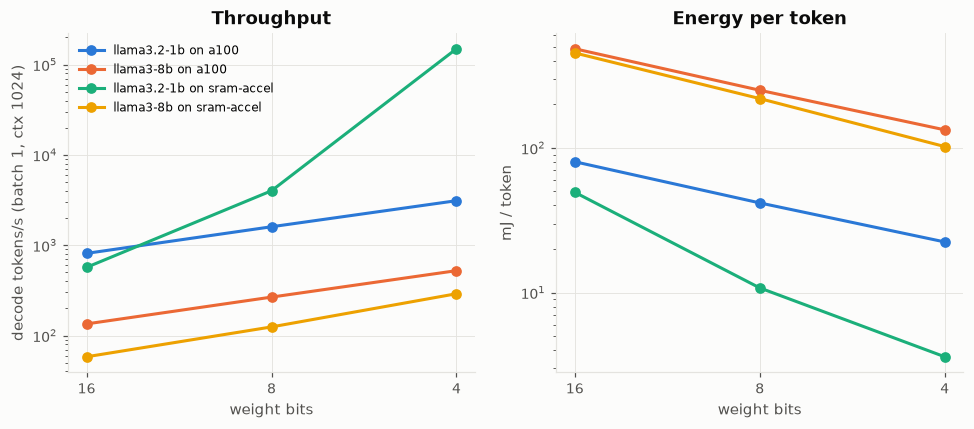

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
q = quant[quant.batch == 1]
i = 0
for cn in ["a100", "sram-accel"]:
    for name in ["llama3.2-1b", "llama3-8b"]:
        g = q[(q.chip == cn) & (q.model == name)].sort_values("weight_bits", ascending=False)
        lbl = f"{name} on {cn}"
        xs = [str(w) for w in g.weight_bits]
        axes[0].plot(xs, g.tokens_per_s, marker="o", color=ps.SERIES[i], label=lbl)
        axes[1].plot(xs, g.mJ_per_token, marker="o", color=ps.SERIES[i], label=lbl)
        i += 1
axes[0].set(yscale="log", xlabel="weight bits", ylabel="decode tokens/s (batch 1, ctx 1024)",
            title="Throughput")
axes[1].set(yscale="log", xlabel="weight bits", ylabel="mJ / token", title="Energy per token")
axes[0].legend(fontsize=8)
ps.save(fig, "design_quantization");

**Answer.** On a GPU at batch 1, decode is weight-bandwidth-bound, so
16 → 8 → 4 bit gives **≈ 2x and ≈ 3.8x** tokens/s and cuts energy per token by
about the same factor, because DRAM bytes dominate decode energy. It's less
than 4x because KV, activations and norms stay 16-bit. At batch 64 the gain
shrinks: KV traffic is unchanged and the matmuls drift toward compute-bound.
(Weight-only quantization doesn't reduce FLOPs here, since the model computes
in bf16.)

On the SRAM chip, quantization is a **capacity** decision more than a
bandwidth one. 1B at 16-bit (2.3 GiB) spills more than half its bytes to the
0.8 TB/s DRAM and is *slower than an A100* (569 vs 813 tok/s). 8-bit
(1.15 GiB) spills only a little and reaches ~4,000 tok/s. At 4-bit the model
fits and throughput jumps another **≈ 37x**. 8B never fits, so the SRAM chip
is a worse 8B decoder than an A100 at every precision. Batching can even
*hurt* there: at batch 64 the KV cache (≈ 2 GiB at ctx 1024) overflows SRAM,
and 4-bit 1B drops from ~150k to ~30k tok/s. That is a strong argument for KV
quantization or KV in a separate memory on such designs.

## 4. Speculative decoding: several tokens verified per weight read

A verify step processes $k+1$ tokens per sequence (`n_new = k+1`) with the
same weight read as one decode step. If each draft token is accepted
independently with probability $\alpha$, the expected number of tokens per
step is $(1-\alpha^{k+1})/(1-\alpha)$ (Leviathan et al., ICML 2023).

* **with draft:** draft = Llama 3.2 1B (k decode steps), target = Llama 3 8B, A100, ctx 1024.
* **ideal:** draft cost 0 (an upper bound; close to self-speculative / Medusa-style heads).

speedup_ideal             speedup_with_draft            
k                       2     4     8                  2     4     8
batch alpha                                                         
1     0.7            2.19  2.76  3.18               1.64  1.67  1.37
      0.9            2.71  4.08  6.09               2.03  2.46  2.63
16    0.7            2.15  2.66  2.95               1.59  1.59  1.28
      0.9            2.65  3.93  5.65               1.97  2.34  2.45
128   0.7            1.28  1.11  0.78               1.03  0.83  0.55
      0.9            1.59  1.64  1.50               1.27  1.22  1.05

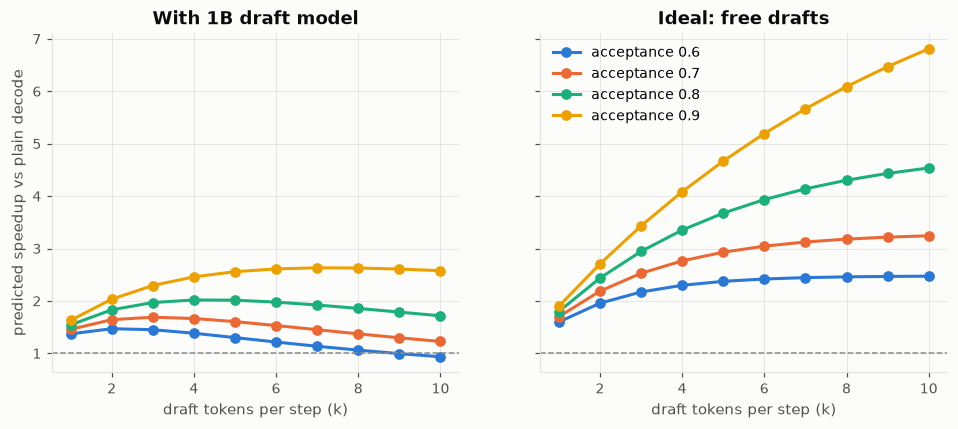

In [9]:
t8, d1, a100 = load_model("llama3-8b"), load_model("llama3.2-1b"), load_chip("a100")
def spec(batch, k, alpha, draft=True, ctx=1024):
    base = predict_step(t8, a100, batch, ctx, 1).time_s / 1           # s per token (per seq)
    verify = predict_step(t8, a100, batch, ctx, k + 1).time_s
    dcost = k * predict_step(d1, a100, batch, ctx, 1).time_s if draft else 0.0
    tokens = (1 - alpha ** (k + 1)) / (1 - alpha)
    return base / ((verify + dcost) / tokens)

ks = np.arange(1, 11)
alphas = [0.6, 0.7, 0.8, 0.9]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4), sharey=True)
for j, draft in enumerate([True, False]):
    for i, a in enumerate(alphas):
        axes[j].plot(ks, [spec(1, int(k), a, draft) for k in ks], marker="o",
                     color=ps.SERIES[i], label=f"acceptance {a}")
    axes[j].axhline(1, color=ps.NEUTRAL, ls="--", lw=1)
    axes[j].set(xlabel="draft tokens per step (k)",
                title=["With 1B draft model", "Ideal: free drafts"][j])
axes[0].set_ylabel("predicted speedup vs plain decode")
axes[1].legend()
ps.save(fig, "design_speculative");

table = pd.DataFrame([{"batch": b, "alpha": a, "k": k,
                       "speedup_with_draft": spec(b, k, a), "speedup_ideal": spec(b, k, a, False)}
                      for b in [1, 16, 128] for a in [0.7, 0.9] for k in [2, 4, 8]])
table.pivot_table(index=["batch", "alpha"], columns="k",
                  values=["speedup_with_draft", "speedup_ideal"]).round(2)

**Answer.** At batch 1 the verify step is nearly free. Checking 5 tokens costs
about the same as generating 1, because the step is weight-bandwidth-bound.
So the gain is roughly the expected accepted length, minus draft cost:
**≈ 1.6x at α = 0.7 and ≈ 2.5x at α = 0.9 with a real 1B draft** (the draft's
own weight reads cap it, so the optimum is k ≈ 3-7), and **≈ 3x / 6x with free
drafts** at k = 8. The benefit drops
quickly with batch. At batch 128 the target's matmuls are already near the
ridge, so verifying k+1 tokens costs nearly k+1 times as much, and the speedup
collapses toward (or below) 1. Speculative decoding is a small-batch,
memory-bound optimization. That is also the regime where an SRAM-heavy chip
benefits least, since its weight reads are already cheap.